# Actividad formativa 2
## Simulación y análisis de señales con la Transformada de Fourier

**Asignatura:** Señales y Sistemas

**Estudiante:** [Tu nombre completo]

### Objetivo
Analizar señales en el dominio del tiempo y de la frecuencia mediante la Transformada de Fourier, utilizando Python para generar señales, calcular sus espectros y comprobar las principales propiedades de esta transformación.

### Herramientas
- Python
- Jupyter Notebook
- NumPy
- SciPy
- Matplotlib

In [1]:
# Importación de bibliotecas para el análisis de señales

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

# Configuración de las gráficas
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True

print("Bibliotecas importadas correctamente.")

Matplotlib is building the font cache; this may take a moment.


Bibliotecas importadas correctamente.


In [2]:
# Parámetros generales de la simulación

frecuencia_muestreo = 1000  # Hz
duracion = 1                # segundos

# Vector de tiempo
tiempo = np.arange(
    0,
    duracion,
    1 / frecuencia_muestreo
)

# Número de muestras
numero_muestras = len(tiempo)

print("Frecuencia de muestreo:", frecuencia_muestreo, "Hz")
print("Duración:", duracion, "segundos")
print("Número de muestras:", numero_muestras)

Frecuencia de muestreo: 1000 Hz
Duración: 1 segundos
Número de muestras: 1000


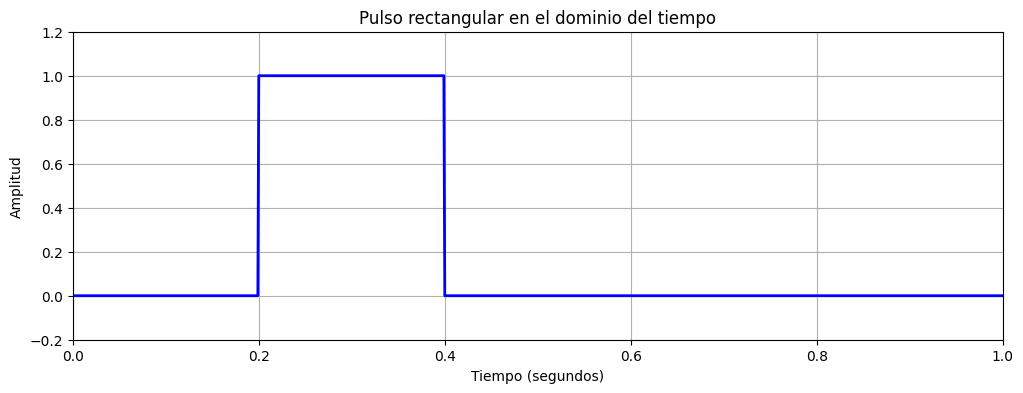

In [3]:
# Generación del pulso rectangular

pulso_rectangular = np.zeros(numero_muestras)

# Definir el intervalo donde el pulso tendrá amplitud 1
inicio_pulso = 0.2
fin_pulso = 0.4

pulso_rectangular[
    (tiempo >= inicio_pulso) &
    (tiempo < fin_pulso)
] = 1

# Graficar el pulso rectangular
plt.figure(figsize=(12, 4))

plt.plot(
    tiempo,
    pulso_rectangular,
    linewidth=2,
    color='blue'
)

plt.title("Pulso rectangular en el dominio del tiempo")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.xlim(0, 1)
plt.ylim(-0.2, 1.2)
plt.grid(True)

plt.show()

In [4]:
# Transformada de Fourier del pulso rectangular

fft_pulso = np.fft.fft(pulso_rectangular)

# Obtener las frecuencias correspondientes
frecuencias = np.fft.fftfreq(
    numero_muestras,
    d=1 / frecuencia_muestreo
)

# Calcular magnitud normalizada
magnitud_pulso = np.abs(fft_pulso) / numero_muestras

# Calcular fase en radianes
fase_pulso = np.angle(fft_pulso)

# Conservar únicamente las frecuencias positivas
indices_positivos = frecuencias >= 0

frecuencias_positivas = frecuencias[indices_positivos]
magnitud_positiva = magnitud_pulso[indices_positivos]
fase_positiva = fase_pulso[indices_positivos]

print("Transformada de Fourier calculada correctamente.")

Transformada de Fourier calculada correctamente.


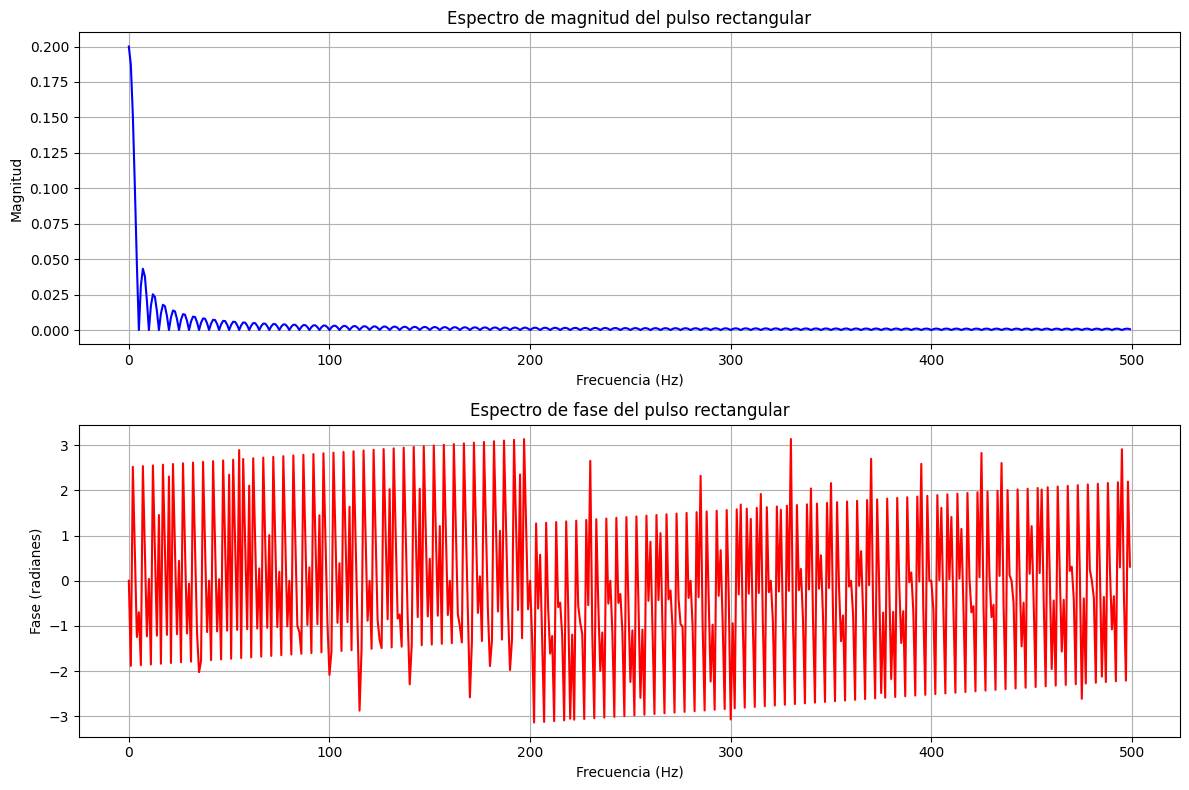

In [5]:
# Representación del espectro de magnitud y fase

plt.figure(figsize=(12, 8))

# Espectro de magnitud
plt.subplot(2, 1, 1)

plt.plot(
    frecuencias_positivas,
    magnitud_positiva,
    color='blue'
)

plt.title("Espectro de magnitud del pulso rectangular")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.grid(True)

# Espectro de fase
plt.subplot(2, 1, 2)

plt.plot(
    frecuencias_positivas,
    fase_positiva,
    color='red'
)

plt.title("Espectro de fase del pulso rectangular")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Fase (radianes)")
plt.grid(True)

plt.tight_layout()
plt.savefig(
    "resultados/pulso_rectangular_espectro.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

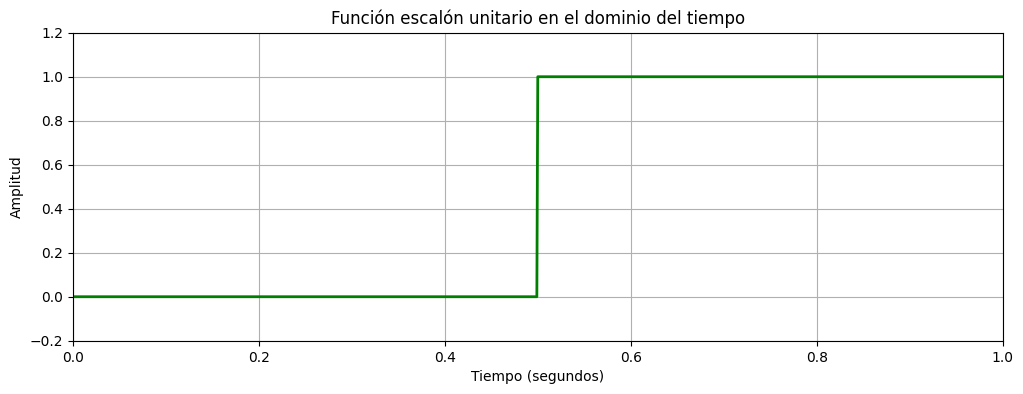

In [6]:
# Generación de la función escalón unitario

funcion_escalon = np.zeros(numero_muestras)

# El escalón comienza en 0.5 segundos
instante_escalon = 0.5

funcion_escalon[tiempo >= instante_escalon] = 1

# Graficar la función escalón
plt.figure(figsize=(12, 4))

plt.plot(
    tiempo,
    funcion_escalon,
    color='green',
    linewidth=2
)

plt.title("Función escalón unitario en el dominio del tiempo")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.xlim(0, 1)
plt.ylim(-0.2, 1.2)
plt.grid(True)

plt.savefig(
    "resultados/funcion_escalon.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [7]:
# Transformada de Fourier de la función escalón

fft_escalon = np.fft.fft(funcion_escalon)

# Calcular magnitud normalizada y fase
magnitud_escalon = np.abs(fft_escalon) / numero_muestras
fase_escalon = np.angle(fft_escalon)

# Seleccionar frecuencias positivas
magnitud_escalon_positiva = magnitud_escalon[indices_positivos]
fase_escalon_positiva = fase_escalon[indices_positivos]

print("Transformada de Fourier del escalón calculada correctamente.")

Transformada de Fourier del escalón calculada correctamente.


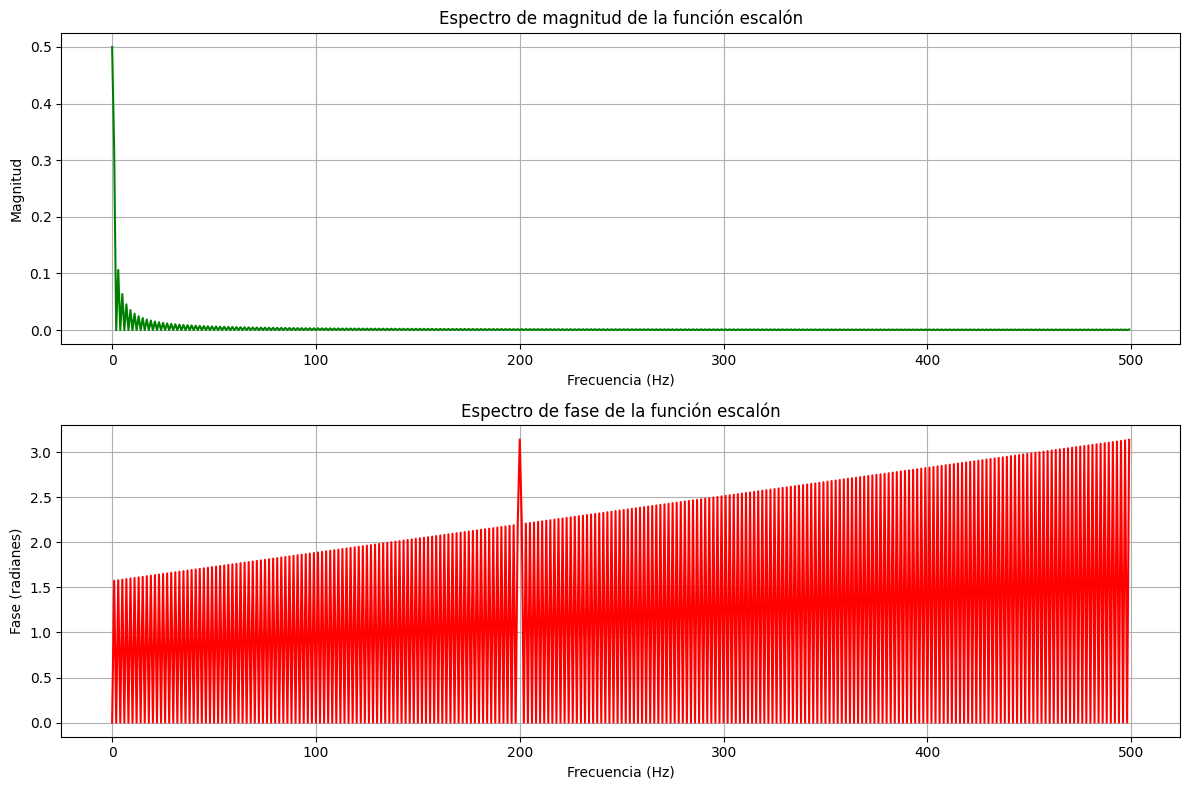

In [8]:
# Representación del espectro de magnitud y fase del escalón

plt.figure(figsize=(12, 8))

# Espectro de magnitud
plt.subplot(2, 1, 1)

plt.plot(
    frecuencias_positivas,
    magnitud_escalon_positiva,
    color='green'
)

plt.title("Espectro de magnitud de la función escalón")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.grid(True)

# Espectro de fase
plt.subplot(2, 1, 2)

plt.plot(
    frecuencias_positivas,
    fase_escalon_positiva,
    color='red'
)

plt.title("Espectro de fase de la función escalón")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Fase (radianes)")
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "resultados/espectro_funcion_escalon.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

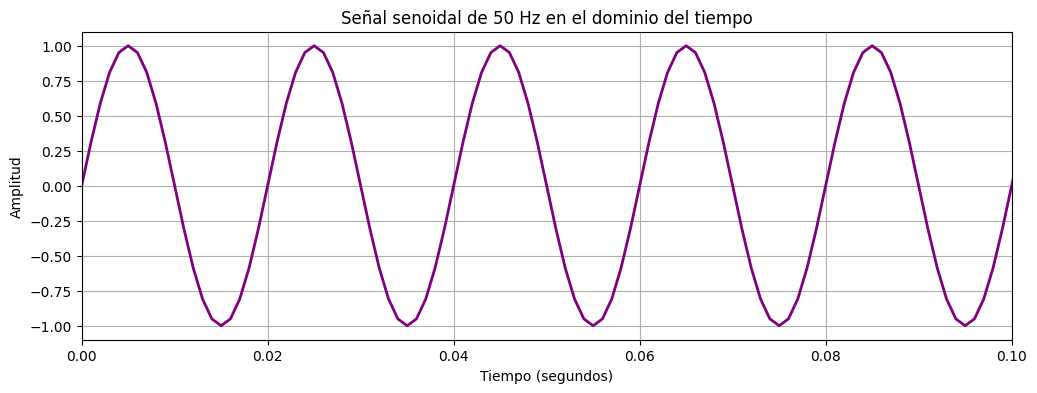

In [9]:
# Generación de la señal senoidal

frecuencia_senoidal = 50
amplitud_senoidal = 1

senal_senoidal = amplitud_senoidal * np.sin(
    2 * np.pi * frecuencia_senoidal * tiempo
)

# Graficar la señal senoidal
plt.figure(figsize=(12, 4))

plt.plot(
    tiempo,
    senal_senoidal,
    color='purple',
    linewidth=2
)

plt.title("Señal senoidal de 50 Hz en el dominio del tiempo")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.xlim(0, 0.1)
plt.grid(True)

plt.savefig(
    "resultados/senal_senoidal.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Transformada de Fourier de la señal senoidal

fft_senoidal = np.fft.fft(senal_senoidal)

# Calcular magnitud normalizada y fase
magnitud_senoidal = np.abs(fft_senoidal) / numero_muestras
fase_senoidal = np.angle(fft_senoidal)

# Seleccionar frecuencias positivas
magnitud_senoidal_positiva = magnitud_senoidal[indices_positivos]
fase_senoidal_positiva = fase_senoidal[indices_positivos]

print("Transformada de Fourier de la señal senoidal calculada correctamente.")

Transformada de Fourier de la señal senoidal calculada correctamente.


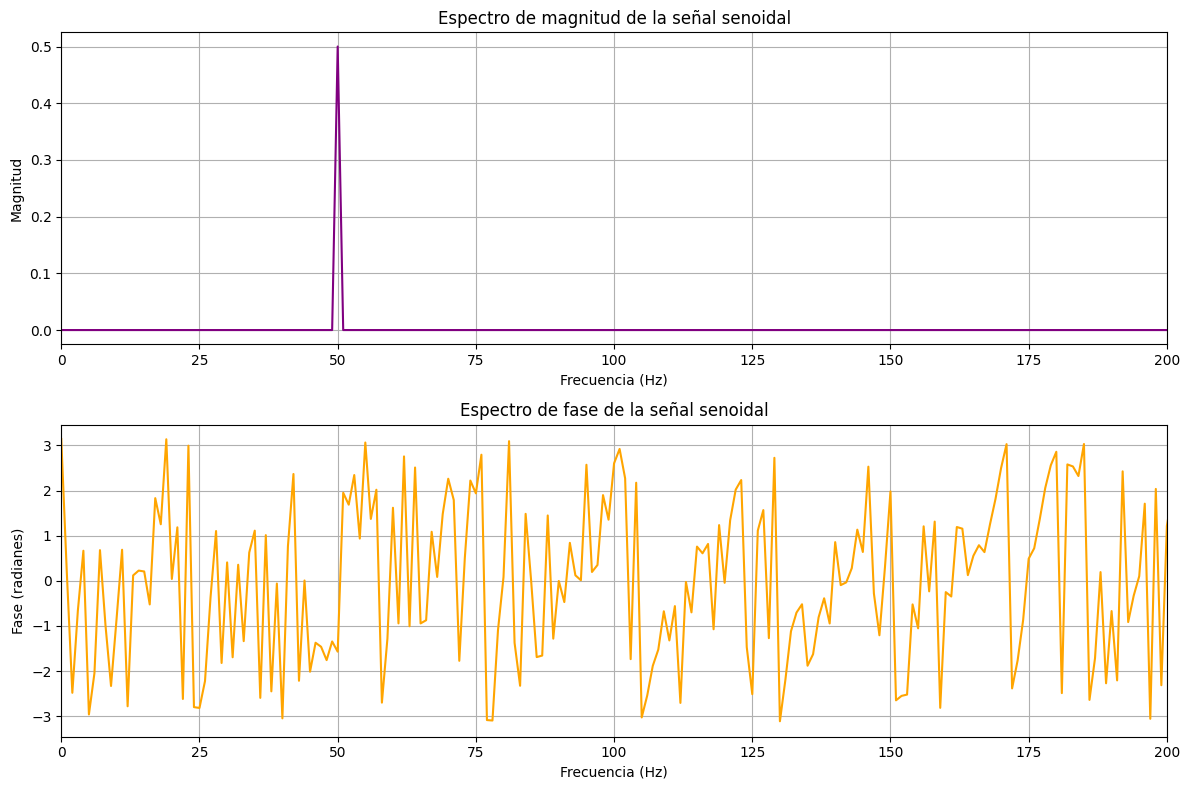

In [11]:
# Representación del espectro de magnitud y fase

plt.figure(figsize=(12, 8))

# Espectro de magnitud
plt.subplot(2, 1, 1)

plt.plot(
    frecuencias_positivas,
    magnitud_senoidal_positiva,
    color='purple'
)

plt.title("Espectro de magnitud de la señal senoidal")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.xlim(0, 200)
plt.grid(True)

# Espectro de fase
plt.subplot(2, 1, 2)

plt.plot(
    frecuencias_positivas,
    fase_senoidal_positiva,
    color='orange'
)

plt.title("Espectro de fase de la señal senoidal")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Fase (radianes)")
plt.xlim(0, 200)
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "resultados/espectro_senal_senoidal.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

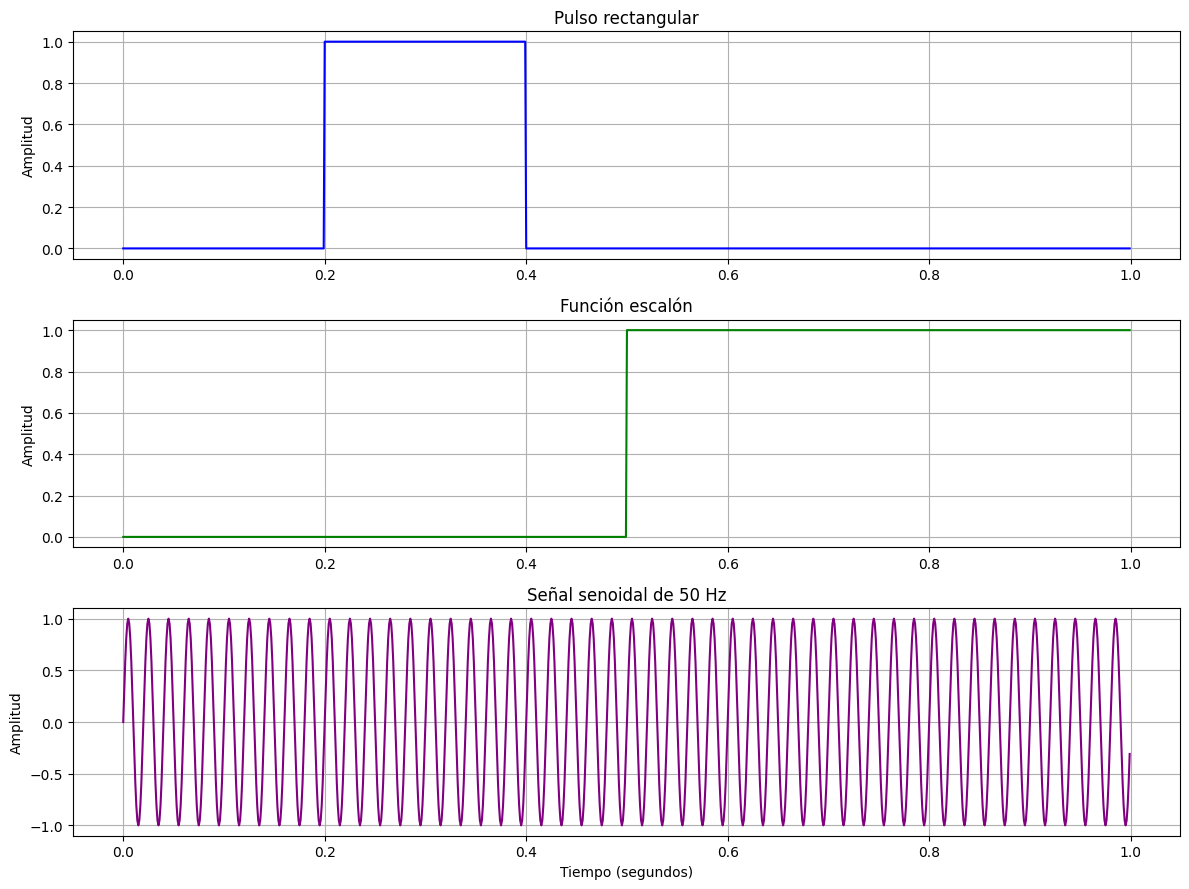

In [12]:
# Comparación de las señales en el dominio del tiempo

plt.figure(figsize=(12, 9))

plt.subplot(3, 1, 1)
plt.plot(tiempo, pulso_rectangular, color='blue')
plt.title("Pulso rectangular")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(tiempo, funcion_escalon, color='green')
plt.title("Función escalón")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(tiempo, senal_senoidal, color='purple')
plt.title("Señal senoidal de 50 Hz")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "resultados/comparacion_dominio_tiempo.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [13]:
# Propiedad de linealidad de la Transformada de Fourier

# Crear una segunda señal senoidal de 100 Hz
senal_100hz = np.sin(2 * np.pi * 100 * tiempo)

# Definir constantes
a = 2
b = 3

# Combinar las señales
senal_combinada = a * senal_senoidal + b * senal_100hz

# Calcular las transformadas individuales
fft_50hz = np.fft.fft(senal_senoidal)
fft_100hz = np.fft.fft(senal_100hz)

# Calcular la transformada de la combinación
fft_combinada = np.fft.fft(senal_combinada)

# Aplicar la propiedad de linealidad
fft_linealidad = a * fft_50hz + b * fft_100hz

# Calcular el error entre ambos resultados
error_linealidad = np.max(
    np.abs(fft_combinada - fft_linealidad)
)

print("Error máximo de linealidad:", error_linealidad)
print("¿Se cumple la propiedad?:",
      np.allclose(fft_combinada, fft_linealidad))

Error máximo de linealidad: 2.305675527551273e-13
¿Se cumple la propiedad?: True


In [14]:
# Propiedad de desplazamiento en el tiempo

desplazamiento = 0.1  # segundos

# Crear una señal senoidal desplazada
senal_desplazada = np.sin(
    2 * np.pi * frecuencia_senoidal * (tiempo - desplazamiento)
)

# Calcular las transformadas
fft_original = np.fft.fft(senal_senoidal)
fft_desplazada = np.fft.fft(senal_desplazada)

# Comparar las magnitudes
magnitud_original = np.abs(fft_original)
magnitud_desplazada = np.abs(fft_desplazada)

# Calcular el error entre las magnitudes
error_desplazamiento = np.max(
    np.abs(magnitud_original - magnitud_desplazada)
)

print("Error máximo de magnitud:", error_desplazamiento)
print(
    "¿Se conserva la magnitud?:",
    np.allclose(magnitud_original, magnitud_desplazada)
)

Error máximo de magnitud: 1.2793987344352058e-12
¿Se conserva la magnitud?: True


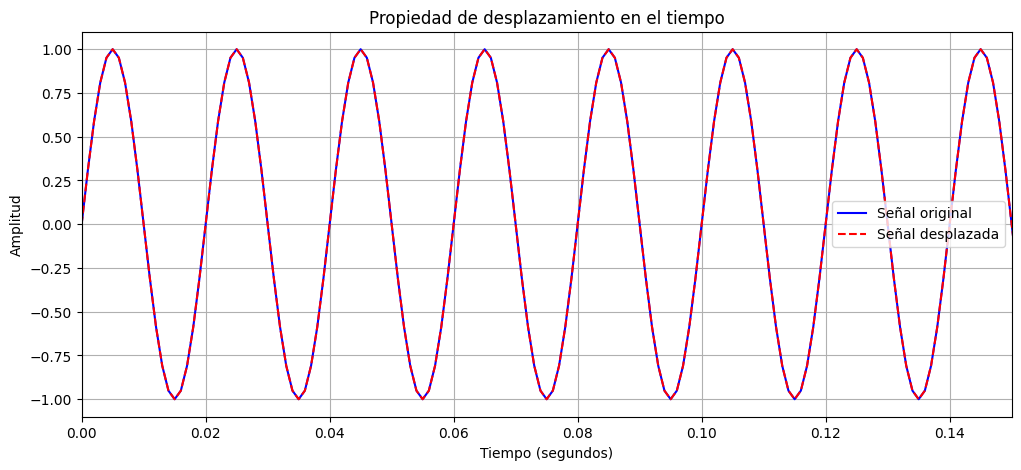

In [15]:
# Comparación de la señal original y desplazada

plt.figure(figsize=(12, 5))

plt.plot(
    tiempo,
    senal_senoidal,
    label="Señal original",
    color="blue"
)

plt.plot(
    tiempo,
    senal_desplazada,
    label="Señal desplazada",
    color="red",
    linestyle="--"
)

plt.title("Propiedad de desplazamiento en el tiempo")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.xlim(0, 0.15)
plt.legend()
plt.grid(True)

plt.savefig(
    "resultados/desplazamiento_temporal.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

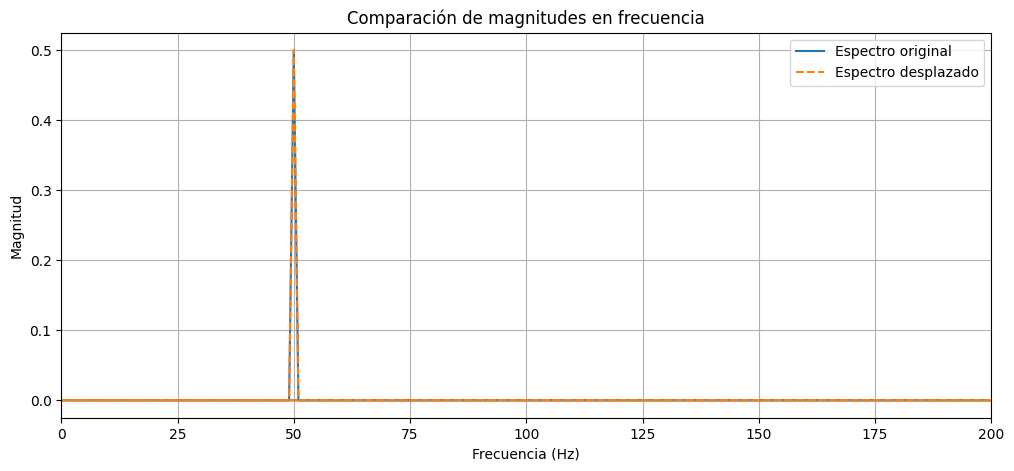

In [16]:
# Comparación de los espectros de magnitud

plt.figure(figsize=(12, 5))

plt.plot(
    frecuencias,
    magnitud_original / numero_muestras,
    label="Espectro original"
)

plt.plot(
    frecuencias,
    magnitud_desplazada / numero_muestras,
    linestyle="--",
    label="Espectro desplazado"
)

plt.title("Comparación de magnitudes en frecuencia")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.xlim(0, 200)
plt.legend()
plt.grid(True)

plt.savefig(
    "resultados/espectro_desplazamiento.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [17]:
# Propiedad de escalamiento en frecuencia

factor_escalamiento = 2

# Señal original de 50 Hz
senal_50hz = np.sin(2 * np.pi * 50 * tiempo)

# Señal escalada: duplica la frecuencia a 100 Hz
senal_100hz_escalada = np.sin(
    2 * np.pi * 50 * (factor_escalamiento * tiempo)
)

# Calcular las transformadas
fft_50hz_escalada = np.fft.fft(senal_50hz)
fft_100hz_escalada = np.fft.fft(senal_100hz_escalada)

# Calcular magnitudes normalizadas
magnitud_50hz = np.abs(fft_50hz_escalada) / numero_muestras
magnitud_100hz = np.abs(fft_100hz_escalada) / numero_muestras

print("Frecuencia original: 50 Hz")
print("Frecuencia escalada: 100 Hz")

Frecuencia original: 50 Hz
Frecuencia escalada: 100 Hz


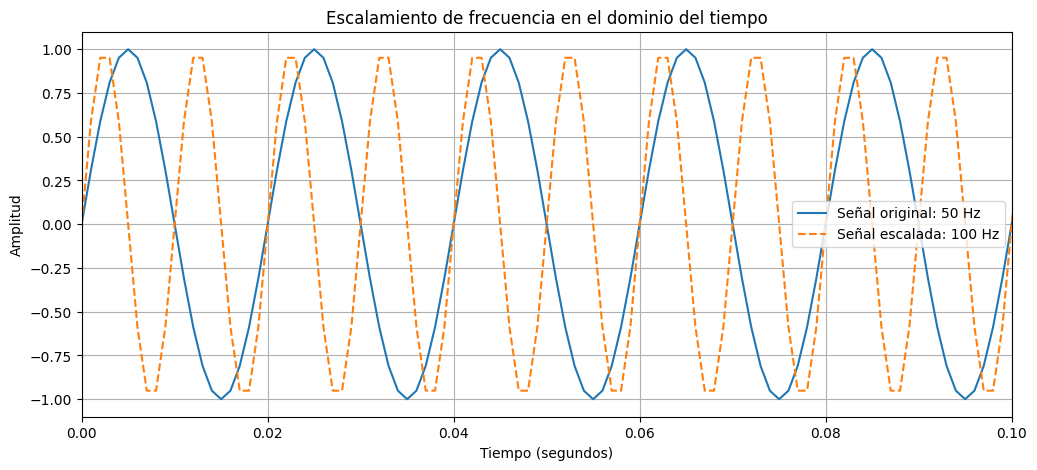

In [18]:
# Comparación de señales con diferentes frecuencias

plt.figure(figsize=(12, 5))

plt.plot(
    tiempo,
    senal_50hz,
    label="Señal original: 50 Hz"
)

plt.plot(
    tiempo,
    senal_100hz_escalada,
    label="Señal escalada: 100 Hz",
    linestyle="--"
)

plt.title("Escalamiento de frecuencia en el dominio del tiempo")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.xlim(0, 0.1)
plt.legend()
plt.grid(True)

plt.savefig(
    "resultados/escalamiento_tiempo.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

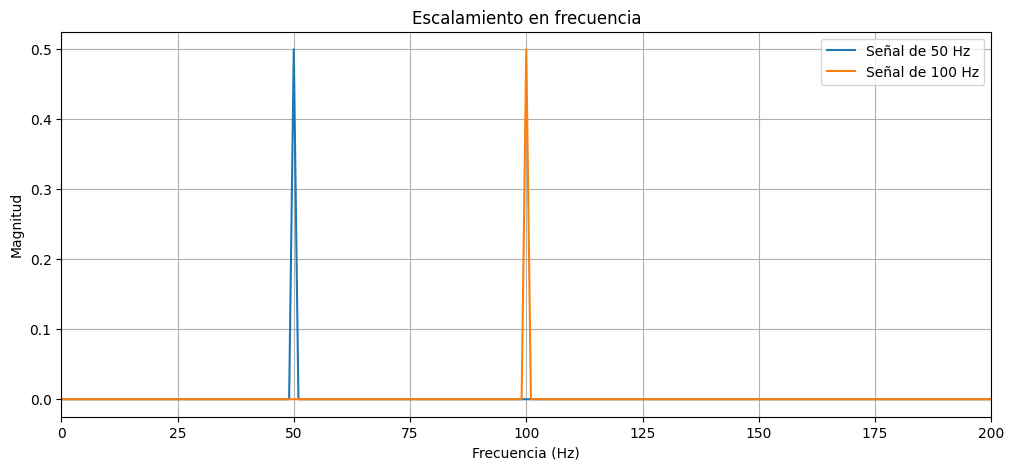

In [19]:
# Comparación de espectros de frecuencia

plt.figure(figsize=(12, 5))

plt.plot(
    frecuencias_positivas,
    magnitud_50hz[indices_positivos],
    label="Señal de 50 Hz"
)

plt.plot(
    frecuencias_positivas,
    magnitud_100hz[indices_positivos],
    label="Señal de 100 Hz"
)

plt.title("Escalamiento en frecuencia")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.xlim(0, 200)
plt.legend()
plt.grid(True)

plt.savefig(
    "resultados/escalamiento_frecuencia.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

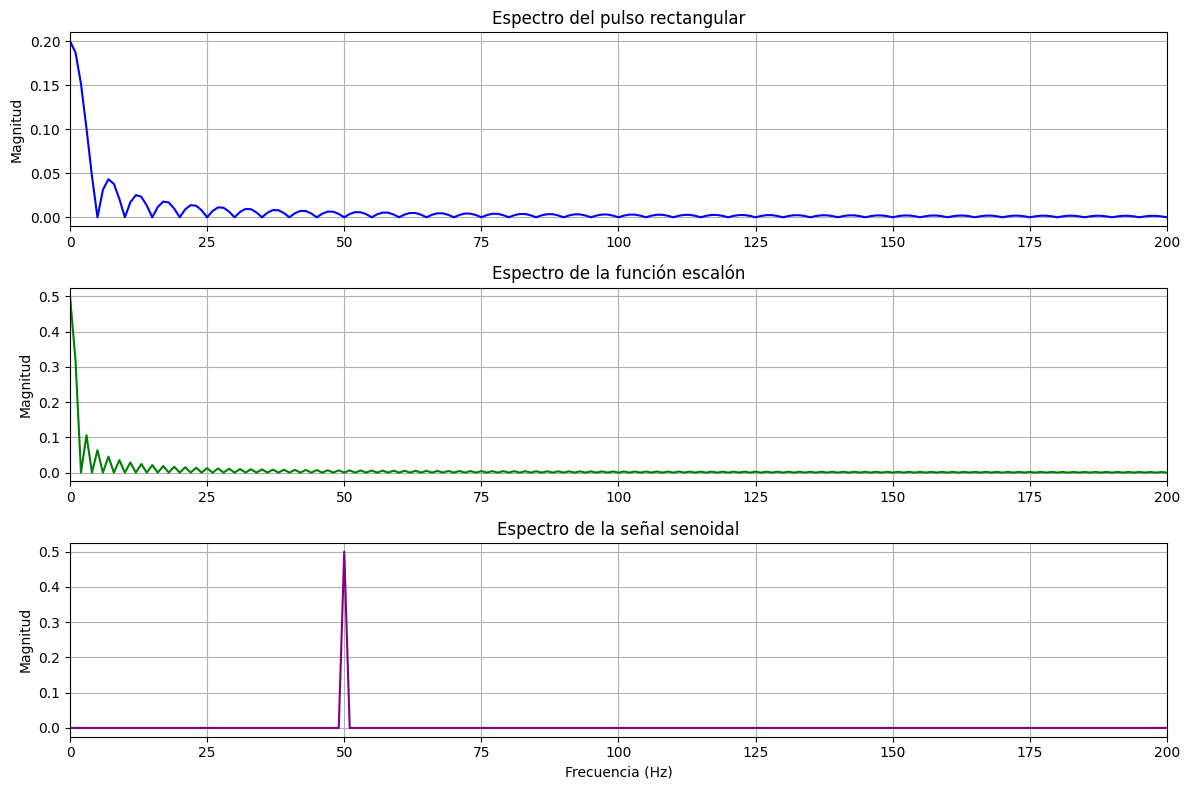

In [20]:
# Comparación de los espectros de las tres señales

plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(
    frecuencias_positivas,
    magnitud_positiva,
    color='blue'
)
plt.title("Espectro del pulso rectangular")
plt.ylabel("Magnitud")
plt.xlim(0, 200)
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(
    frecuencias_positivas,
    magnitud_escalon_positiva,
    color='green'
)
plt.title("Espectro de la función escalón")
plt.ylabel("Magnitud")
plt.xlim(0, 200)
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(
    frecuencias_positivas,
    magnitud_senoidal_positiva,
    color='purple'
)
plt.title("Espectro de la señal senoidal")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.xlim(0, 200)
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "resultados/comparacion_espectros.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [21]:
# Identificar las frecuencias dominantes

indice_50 = np.argmax(magnitud_50hz[indices_positivos])
indice_100 = np.argmax(magnitud_100hz[indices_positivos])

frecuencia_detectada_50 = frecuencias_positivas[indice_50]
frecuencia_detectada_100 = frecuencias_positivas[indice_100]

print("Frecuencia original:", frecuencia_detectada_50, "Hz")
print("Frecuencia escalada:", frecuencia_detectada_100, "Hz")

Frecuencia original: 50.0 Hz
Frecuencia escalada: 100.0 Hz


# Análisis e interpretación de resultados

## 1. Análisis de las señales en el dominio del tiempo

Durante la simulación se generaron tres señales elementales:

- Pulso rectangular: mantiene una amplitud constante durante un intervalo de tiempo y posteriormente regresa a cero.
- Función escalón: presenta un cambio de amplitud de cero a uno a partir de 0.5 segundos.
- Señal senoidal: presenta un comportamiento periódico con una frecuencia de 50 Hz y amplitud de 1.

Cada señal presenta características diferentes en el dominio del tiempo, lo que permite estudiar su comportamiento al aplicar la Transformada de Fourier.

## 2. Análisis en el dominio de la frecuencia

La Transformada de Fourier permitió identificar cómo se distribuyen las componentes frecuenciales de cada señal.

El pulso rectangular presenta diferentes componentes de frecuencia, con una magnitud que disminuye conforme aumenta la frecuencia.

La función escalón presenta una componente continua importante y otras componentes distribuidas en el espectro.

La señal senoidal presenta un pico claramente definido en 50 Hz, lo que confirma su frecuencia principal.

## 3. Verificación de las propiedades de Fourier

### Linealidad

Se comprobó que la transformada de una combinación lineal de señales coincide con la combinación lineal de sus transformadas. El resultado obtenido fue True.

### Desplazamiento en el tiempo

Se comprobó que el desplazamiento temporal conserva la magnitud del espectro y modifica su fase. En la simulación se utilizó un desplazamiento de 0.1 segundos, equivalente a cinco ciclos completos de la señal de 50 Hz.

### Escalamiento en frecuencia

Se comprobó que al duplicar la frecuencia de una señal de 50 Hz se obtiene una señal de 100 Hz. Los picos del espectro permitieron identificar ambas frecuencias.

## 4. Comparación general

Los resultados muestran que la representación en el dominio del tiempo permite observar la evolución de una señal, mientras que el dominio de la frecuencia permite identificar las componentes frecuenciales que la forman.

La Transformada de Fourier facilita el análisis de señales que presentan diferentes características y permite comprobar matemáticamente propiedades fundamentales del procesamiento digital de señales.

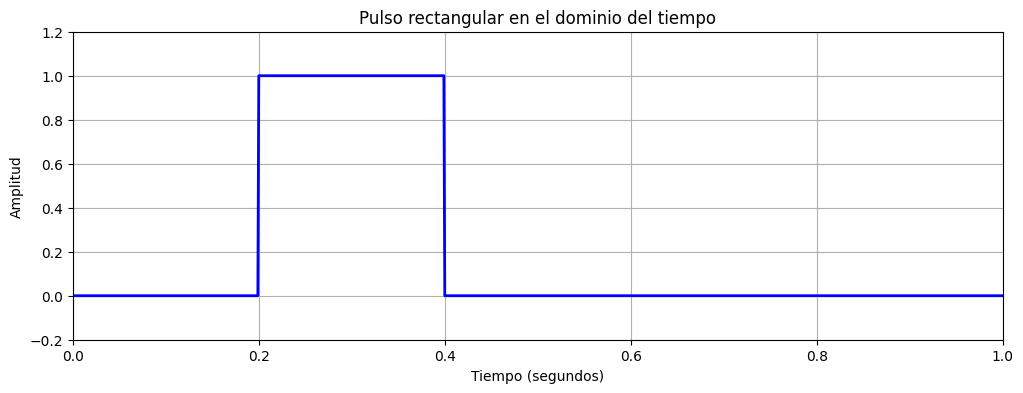

In [22]:
# Guardar la gráfica del pulso rectangular

plt.figure(figsize=(12, 4))

plt.plot(
    tiempo,
    pulso_rectangular,
    color='blue',
    linewidth=2
)

plt.title("Pulso rectangular en el dominio del tiempo")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.xlim(0, 1)
plt.ylim(-0.2, 1.2)
plt.grid(True)

plt.savefig(
    "resultados/pulso_rectangular.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()